<a href="https://colab.research.google.com/github/BagasArdiansaPutra/Pembelajaran-Mesin-2026/blob/main/TG6_Regresi_244107020166_Bagas_Ardiansa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#JS06 - Regresi

#Praktikum1

In [1]:
# import package
import numpy as np
import pandas as pd

In [2]:
# baca data dari file CSV
data = pd.read_csv('/content/dataset.csv')

In [3]:
# melihat beberapa data awal
data.head()

# mengecek ukuran data
data.shape

# informasi tentang data
data.info()

# deskripsi data
data.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [4]:
# import library untuk visualisasi
import matplotlib.pyplot as plt
import seaborn as sns

/usr/local/lib/python3.13/dist-packages/seaborn/axisgrid.py:2100: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


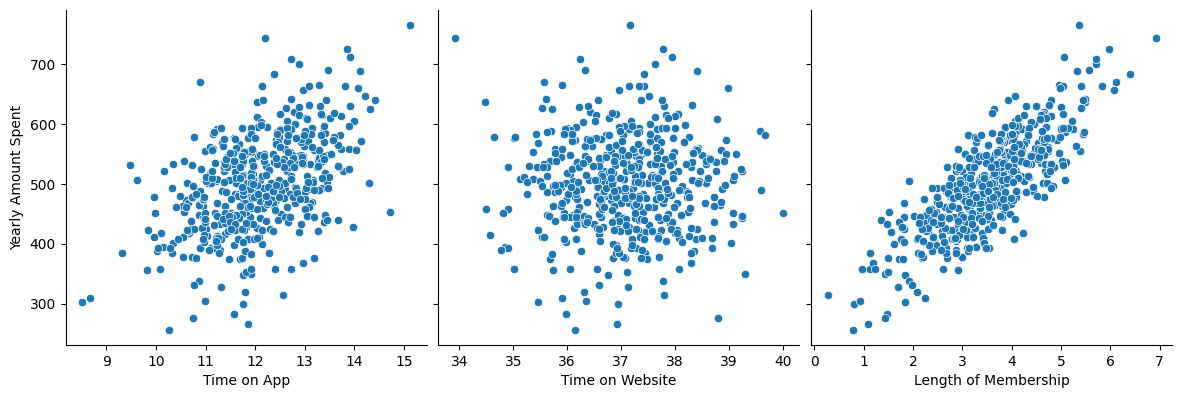

In [5]:
# visualisasi data dengan pairplot
sns.pairplot(data, x_vars=['Time on App', 'Time on Website', 'Length of Membership'],
             y_vars='Yearly Amount Spent', size=4, aspect=1, kind='scatter')
plt.show()

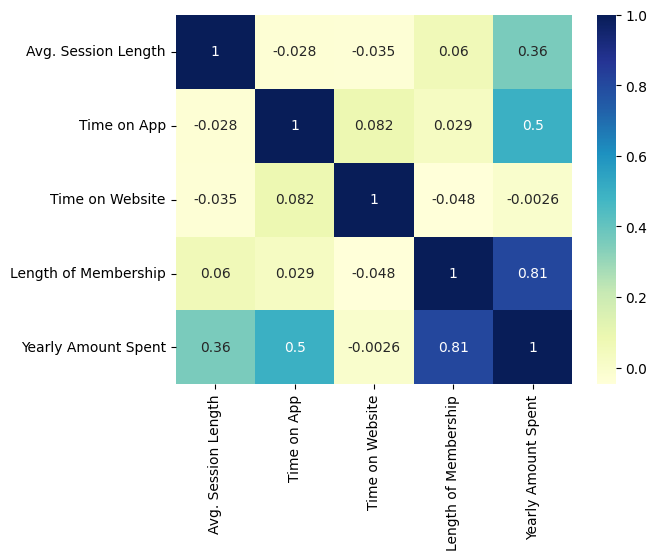

In [16]:
# visualisasi korelasi dengan heatmap
sns.heatmap(data.corr(numeric_only=True), cmap="YlGnBu", annot=True)
plt.show()

In [7]:
# Membuat variabel bebas X dan Y, contoh pengambilan dari analisis korelasi sebelumnya
X = data['Length of Membership']
y = data['Yearly Amount Spent']

In [8]:
# Pembagian data latih dan data uji dengan proporsi 7:3
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, test_size=0.3, random_state=100)

In [9]:
# Training model
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)
lr = sm.OLS(y_train, X_train_sm).fit()

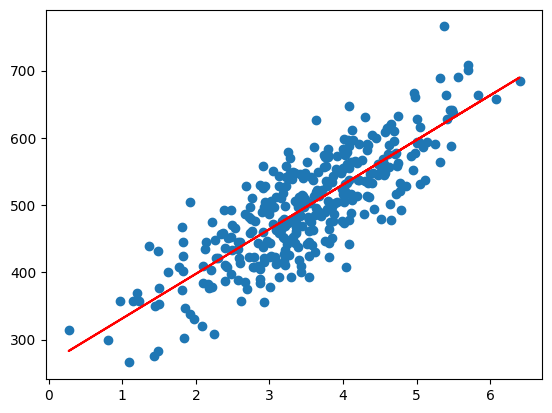

In [10]:
# Visualisasi garis regresi
plt.scatter(X_train, y_train)
plt.plot(X_train, 265.2483 + 66.3015*X_train, 'r')
plt.show()

In [11]:
# Prediksi nilai y_value dari data x yang telah dilatih
y_train_pred = lr.predict(X_train_sm)

# Menghitung residual
res = (y_train - y_train_pred)

/tmp/ipykernel_572/594495671.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res, bins=15)


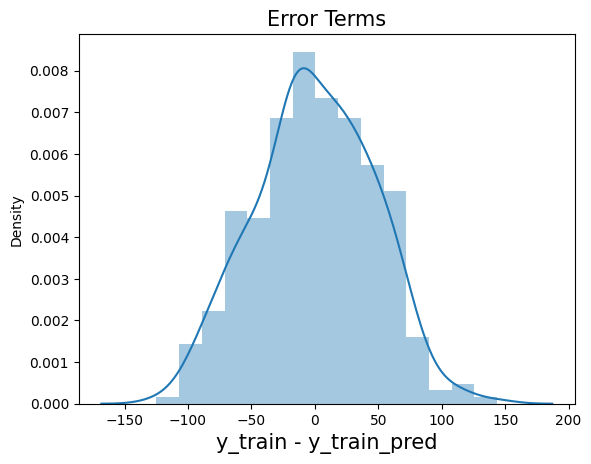

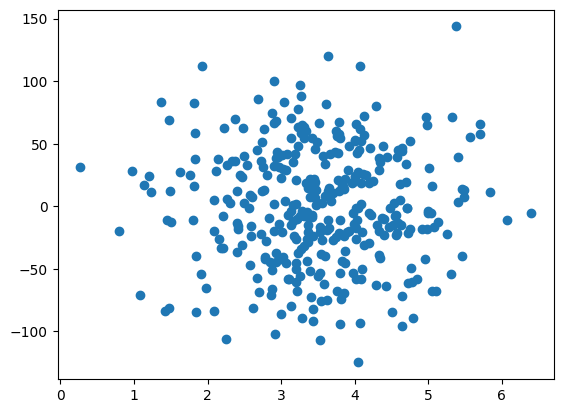

In [12]:
# Histogram residual
fig = plt.figure()
sns.distplot(res, bins=15)
plt.title('Error Terms', fontsize=15)
plt.xlabel('y_train - y_train_pred', fontsize=15)
plt.show()

# Scatter plot residual
plt.scatter(X_train, res)
plt.show()

In [13]:
# Prediksi pada data uji
X_test_sm = sm.add_constant(X_test)
y_test_pred = lr.predict(X_test_sm)

In [14]:
# Hitung nilai R-squared
from sklearn.metrics import r2_score

r_squared = r2_score(y_test, y_test_pred)

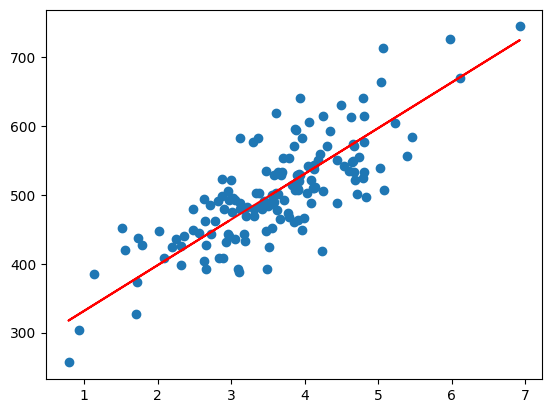

In [15]:
# Visualisasi data uji dan hasil prediksi
plt.scatter(X_test, y_test)
plt.plot(X_test, y_test_pred, 'r')
plt.show()

#Praktikum2


In [17]:
# Mengimpor library
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [18]:
# Mengimpor dataset (Pastikan Anda memiliki file CSV 'Posisi_gaji.csv' dalam direktori yang sama)
dataset = pd.read_csv('/content/Posisi_gaji.csv')
X = dataset.iloc[:, 1:2].values
y = dataset.iloc[:, 2].values  # Ubah menjadi satu kolom saja

In [19]:
# Feature Scaling
from sklearn.preprocessing import StandardScaler
sc_X = StandardScaler()
sc_y = StandardScaler()
X = sc_X.fit_transform(X.reshape(-1, 1))
y = sc_y.fit_transform(y.reshape(-1, 1))

In [20]:
# Fitting SVR ke dataset
from sklearn.svm import SVR
regressor = SVR(kernel='rbf')
regressor.fit(X, y)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

/tmp/ipykernel_572/1841224750.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)


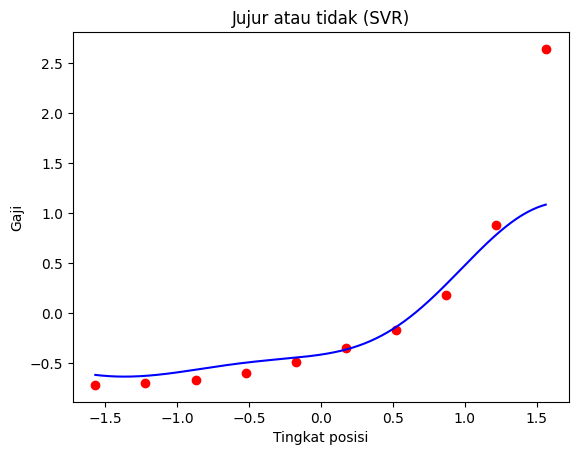

In [21]:
# Visualisasi hasil SVR (resolusi tinggi dan kurva yang lebih halus)
X_grid = np.arange(min(X), max(X), 0.01).reshape(-1, 1)
plt.scatter(X, y, color='red')
plt.plot(X_grid, regressor.predict(X_grid), color='blue')
plt.title('Jujur atau tidak (SVR)')
plt.xlabel('Tingkat posisi')
plt.ylabel('Gaji')
plt.show()

In [22]:
# Prediksi hasil
# Buat array 2D yang berisi tingkat posisi yang akan diprediksi
tingkat_posisi_prediksi = np.array([[6.5]])
# Penskalaan fitur untuk data yang akan diprediksi
tingkat_posisi_prediksi = sc_X.transform(tingkat_posisi_prediksi)
# Melakukan prediksi menggunakan model SVR
gaji_prediksi = regressor.predict(tingkat_posisi_prediksi)
# Kembalikan hasil prediksi ke skala aslinya
gaji_prediksi = sc_y.inverse_transform(gaji_prediksi.reshape(-1, 1))

In [23]:
# Menampilkan hasil prediksi
print("Prediksi Gaji untuk Tingkat Posisi 6.5:", gaji_prediksi[0])

Prediksi Gaji untuk Tingkat Posisi 6.5: [170370.0204065]


In [24]:
# Evaluasi model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_actual = y
y_pred = regressor.predict(X)

# Menghitung MAE
mae = mean_absolute_error(y_actual, y_pred)

# Menghitung MSE
mse = mean_squared_error(y_actual, y_pred)

# Menghitung RMSE
rmse = np.sqrt(mse)

# Menghitung R-squared
r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R-squared:", r2)

MAE: 0.22299274095734414
MSE: 0.24839989293792014
RMSE: 0.4983973243687411
R-squared: 0.7516001070620798


#Tugas Praktikum

In [ ]:
Tugas 1: Multiple Linear Regression

1. Identifikasi variabel-variabel yang akan digunakan sebagai variabel bebas (fitur) dan variabel target (biaya medis personal).

In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

df = pd.read_csv('/content/insurance.csv')

df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Variabel Bebas / Fitur (Independent Variables)
X = df_encoded.drop('charges', axis=1)

# Variabel Target (Dependent Variable)
y = df_encoded['charges']

# Membagi data menjadi data latih (training) dan data uji (testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Inisialisasi dan melatih model Multiple Linear Regression
mlr_model = LinearRegression()
mlr_model.fit(X_train, y_train)

# Melakukan prediksi menggunakan data uji
y_pred = mlr_model.predict(X_test)

# Menampilkan identifikasi variabel dan hasil model
print("Identifikasi Variabel")
print("Variabel Bebas (X):", X.columns.tolist())
print("Variabel Target (y): ['charges']\n")

print("Hasil Model Multiple Linear Regression")
print("Koefisien:")
for fitur, koef in zip(X.columns, mlr_model.coef_):
    print(f" - {fitur}: {koef:.4f}")
print(f"Intercept: {mlr_model.intercept_:.4f}")
print(f"R-squared: {r2_score(y_test, y_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")

Identifikasi Variabel
Variabel Bebas (X): ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
Variabel Target (y): ['charges']

Hasil Model Multiple Linear Regression
Koefisien:
 - age: 256.9757
 - bmi: 337.0926
 - children: 425.2788
 - sex_male: -18.5917
 - smoker_yes: 23651.1289
 - region_northwest: -370.6773
 - region_southeast: -657.8643
 - region_southwest: -809.7994
Intercept: -11931.2191
R-squared: 0.7836
MSE: 33596915.8514


In [ ]:
2. Bagi dataset menjadi data latih (train) dan data uji (test) dengan proporsi yang sesuai.

In [28]:
df_encoded = pd.get_dummies(df, columns=['sex', 'smoker', 'region'], drop_first=True)

# Memisahkan variabel bebas (X) dan variabel target (y)
X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

# Membagi dataset menjadi Data Latih (Train) 80% dan Data Uji (Test) 20%
# random_state=42 digunakan agar hasil pembagian selalu tetap (reproducible)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Total baris dataset asli : {len(df)}")
print(f"Total baris data latih   : {len(X_train)} (80%)")
print(f"Total baris data uji     : {len(X_test)} (20%)")

Total baris dataset asli : 1338
Total baris data latih   : 1070 (80%)
Total baris data uji     : 268 (20%)


In [ ]:
3. Lakukan feature scaling jika diperlukan.

In [30]:
from sklearn.preprocessing import StandardScaler

# Inisialisasi StandardScaler
scaler = StandardScaler()

# Melakukan fit (mencari rata-rata & standar deviasi) dan transformasi pada data latih
X_train_scaled = scaler.fit_transform(X_train)

# Melakukan transformasi pada data uji menggunakan pola skala dari data latih
X_test_scaled = scaler.transform(X_test)


In [ ]:
4. Buat model multiple linear regression menggunakan Scikit-Learn.

In [31]:
from sklearn.linear_model import LinearRegression

# Inisialisasi model Multiple Linear Regression
mlr_model = LinearRegression()

# Melatih model menggunakan data latih yang sudah di-scaling (X_train_scaled) dan y_train
mlr_model.fit(X_train_scaled, y_train)

print("Model Multiple Linear Regression Berhasil Dilatih")
print(f"Intercept: {mlr_model.intercept_:.4f}\n")

print("Koefisien untuk masing-masing fitur:")
for fitur, koef in zip(X.columns, mlr_model.coef_):
    print(f" - {fitur}: {koef:.4f}")

Model Multiple Linear Regression Berhasil Dilatih
Intercept: 13346.0897

Koefisien untuk masing-masing fitur:
 - age: 3614.9754
 - bmi: 2036.2281
 - children: 516.8902
 - sex_male: -9.2931
 - smoker_yes: 9558.4814
 - region_northwest: -158.1410
 - region_southeast: -290.1570
 - region_southwest: -349.1107


In [ ]:
5. Latih model pada data latih dan lakukan prediksi pada data uji.

In [32]:
import pandas as pd
y_pred_mlr = mlr_model.predict(X_test_scaled)

# Membuat DataFrame untuk membandingkan 5 data aktual dan hasil prediksi pertama
hasil_prediksi = pd.DataFrame({
    'Nilai Aktual (y_test)': y_test,
    'Nilai Prediksi (y_pred)': y_pred_mlr
})

# Menampilkan perbandingan
print("Sampel Perbandingan Nilai Aktual vs Prediksi")
print(hasil_prediksi.head())

Sampel Perbandingan Nilai Aktual vs Prediksi
      Nilai Aktual (y_test)  Nilai Prediksi (y_pred)
764              9095.06825              8969.550274
887              5272.17580              7068.747443
890             29330.98315             36858.410912
1293             9301.89355              9454.678501
259             33750.29180             26973.173457


In [ ]:
6. Evaluasi model dengan menghitung metrik seperti R-squared, MSE, dan MAE. Tampilkan hasil evaluasi.

In [33]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Menghitung metrik evaluasi
r2_mlr = r2_score(y_test, y_pred_mlr)
mse_mlr = mean_squared_error(y_test, y_pred_mlr)
mae_mlr = mean_absolute_error(y_test, y_pred_mlr)

print("Evaluasi Model Multiple Linear Regression")
print(f"R-squared (R2) : {r2_mlr:.4f}")
print(f"Mean Squared Error (MSE) : {mse_mlr:.4f}")
print(f"Mean Absolute Error (MAE) : {mae_mlr:.4f}")

Evaluasi Model Multiple Linear Regression
R-squared (R2) : 0.7836
Mean Squared Error (MSE) : 33596915.8514
Mean Absolute Error (MAE) : 4181.1945


#Catatan Tambahan:

1. Pastikan untuk memberikan penjelasan singkat tentang dataset yang digunakan, termasuk deskripsi variabel-variabel yang relevan.

2. Tampilkan visualisasi data yang relevan seperti scatter plot atau grafik lainnya jika diperlukan untuk pemahaman yang lebih baik.

3. Analisis hasil yang Anda dapatkan dalam tugas praktikum Anda.

In [ ]:
1. Identifikasi Variabel

Variabel Target (y): charges (biaya medis personal yang akan diprediksi).

Variabel Bebas/Fitur (X): age (usia), sex (jenis kelamin), bmi (indeks massa tubuh), children (jumlah anak/tanggungan), smoker (status perokok), dan region (wilayah tempat tinggal).

In [ ]:
2. Visualisasi Data

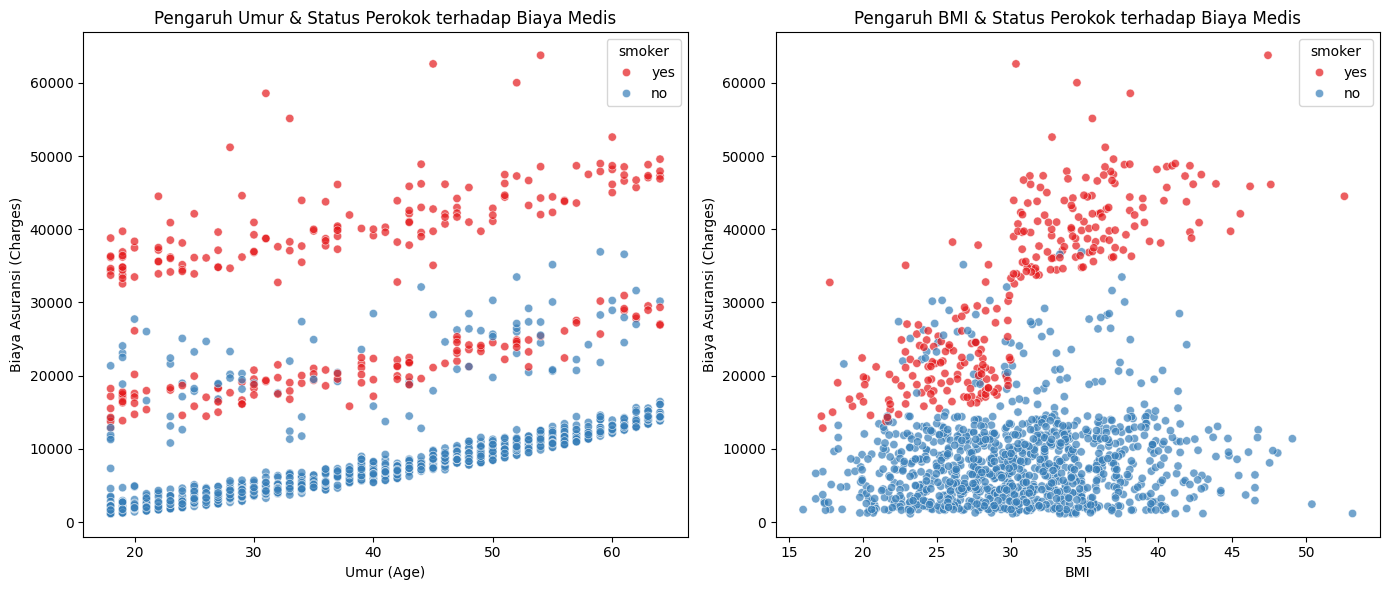

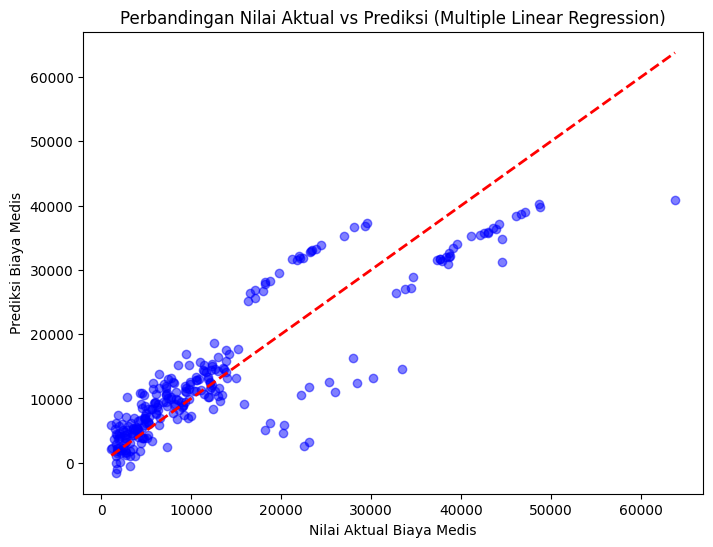

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Memuat data
df = pd.read_csv('/content/insurance.csv')

# --- VISUALISASI EKSPLORASI DATA (EDA) ---
plt.figure(figsize=(14, 6))

# Plot 1: Umur vs Biaya Medis (Dikelompokkan berdasarkan status perokok)
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='age', y='charges', hue='smoker', palette='Set1', alpha=0.7)
plt.title('Pengaruh Umur & Status Perokok terhadap Biaya Medis')
plt.xlabel('Umur (Age)')
plt.ylabel('Biaya Asuransi (Charges)')

# Plot 2: BMI vs Biaya Medis (Dikelompokkan berdasarkan status perokok)
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker', palette='Set1', alpha=0.7)
plt.title('Pengaruh BMI & Status Perokok terhadap Biaya Medis')
plt.xlabel('BMI')
plt.ylabel('Biaya Asuransi (Charges)')

plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_mlr, color='blue', alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2) # Garis diagonal ideal
plt.title('Perbandingan Nilai Aktual vs Prediksi (Multiple Linear Regression)')
plt.xlabel('Nilai Aktual Biaya Medis')
plt.ylabel('Prediksi Biaya Medis')
plt.show()

In [ ]:
3. Evaluasi & Analisis Model

- Hasil Metrik:

  - R-squared: 0.7836 (Model berhasil menjelaskan 78,36% pola data tagihan medis).

  - MSE: 33.596.915 (Rata-rata dari kuadrat kesalahan prediksi).

  - MAE: 4.181,19 (Rata-rata prediksi biaya asuransi meleset sekitar $4.181 dari biaya aslinya).

- Kesimpulan: Model cukup efektif. Berdasarkan koefisien model, status perokok adalah faktor yang paling dominan menaikkan biaya medis, disusul oleh usia yang bertambah dan BMI yang tinggi.